# PHILIP_ANTWI: Student Performance Regression

This notebook uses the fictional `PHILIP_ANTWI.csv` dataset (5,000 students) to demonstrate simple linear regression, multiple linear regression, and logistic regression. The data is synthetic and is for learning purposes only.

The analysis cells use Python's standard library and create the diagnostic plots as SVG, so no extra packages are needed.

In [1]:
import csv
import math
import random
from pathlib import Path
from IPython.display import SVG, display

with Path("PHILIP_ANTWI.csv").open(newline="", encoding="utf-8") as csv_file:
    rows = list(csv.DictReader(csv_file))
for row in rows:
    for name in ("study_hours", "attendance_pct", "previous_score", "assignments_completed_pct", "final_score"):
        row[name] = float(row[name])
    row["passed"] = int(row["passed"])

indices = list(range(len(rows)))
random.Random(42).shuffle(indices)
split = int(len(indices) * 0.8)
train_indices, test_indices = indices[:split], indices[split:]

def solve(matrix, target):
    """Solve normal equations with Gaussian elimination and pivoting."""
    a = [list(map(float, row)) + [float(y)] for row, y in zip(matrix, target)]
    n = len(target)
    for col in range(n):
        pivot = max(range(col, n), key=lambda r: abs(a[r][col]))
        if abs(a[pivot][col]) < 1e-12:
            raise ValueError("Predictor columns are collinear; coefficients cannot be estimated.")
        a[col], a[pivot] = a[pivot], a[col]
        scale = a[col][col]
        a[col] = [v / scale for v in a[col]]
        for r in range(n):
            if r != col:
                factor = a[r][col]
                a[r] = [v - factor * p for v, p in zip(a[r], a[col])]
    return [a[r][-1] for r in range(n)]

def fit_linear(features):
    size = len(features) + 1
    gram, target = [[0.0] * size for _ in range(size)], [0.0] * size
    for i in train_indices:
        x, y = [1.0] + [rows[i][name] for name in features], rows[i]["final_score"]
        for j in range(size):
            target[j] += x[j] * y
            for k in range(size):
                gram[j][k] += x[j] * x[k]
    return solve(gram, target)

def predict(beta, row, features):
    return beta[0] + sum(b * row[name] for b, name in zip(beta[1:], features))

def regression_metrics(actual, predicted):
    mean = sum(actual) / len(actual)
    mse = sum((y - p) ** 2 for y, p in zip(actual, predicted)) / len(actual)
    r2 = 1 - sum((y - p) ** 2 for y, p in zip(actual, predicted)) / sum((y - mean) ** 2 for y in actual)
    return mse, r2

def show_plot(actual, predicted, title):
    """Plot the first 10 test predictions and their residuals as SVG."""
    pairs = list(zip(actual, predicted))[:10]
    errors = [y - p for y, p in pairs]
    lo, hi = min(y for y, _ in pairs), max(y for y, _ in pairs)
    pad = max((hi - lo) * 0.08, 1.0)
    lo, hi = lo - pad, hi + pad
    width, height = 900, 410
    panels = [(65, 65, 330, 270), (500, 65, 330, 270)]
    colors = ["#2563eb", "#dc2626", "#059669", "#9333ea", "#d97706", "#0891b2", "#4f46e5", "#be123c", "#65a30d", "#7c3aed"]
    svg = [f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}">', '<rect width="100%" height="100%" fill="white"/>', f'<text x="450" y="28" text-anchor="middle" font-size="18">{title}: first 10 test observations</text>']
    for panel, (left, top, pw, ph) in enumerate(panels):
        svg.append(f'<rect x="{left}" y="{top}" width="{pw}" height="{ph}" fill="#fafafa" stroke="#9ca3af"/>')
        if panel == 0:
            svg.append(f'<line x1="{left}" y1="{top+ph}" x2="{left+pw}" y2="{top}" stroke="#111827" stroke-dasharray="6,4"/>')
            svg.append(f'<text x="{left+pw/2}" y="{top-12}" text-anchor="middle">Actual vs predicted</text>')
            svg.append(f'<text x="{left+pw/2}" y="{top+ph+35}" text-anchor="middle">Actual score</text>')
        else:
            err_lo, err_hi = min(errors), max(errors)
            err_pad = max((err_hi - err_lo) * 0.12, 1.0)
            err_lo, err_hi = err_lo - err_pad, err_hi + err_pad
            zero_y = top + (err_hi / (err_hi - err_lo)) * ph
            svg.append(f'<line x1="{left}" y1="{zero_y:.1f}" x2="{left+pw}" y2="{zero_y:.1f}" stroke="#111827" stroke-dasharray="6,4"/>')
            svg.append(f'<text x="{left+pw/2}" y="{top-12}" text-anchor="middle">Residual vs predicted</text>')
            svg.append(f'<text x="{left+pw/2}" y="{top+ph+35}" text-anchor="middle">Predicted score</text>')
        for i, ((y, p), error) in enumerate(zip(pairs, errors)):
            if panel == 0:
                x, value, ylo, yhi = y, p, lo, hi
            else:
                x, value, ylo, yhi = p, error, err_lo, err_hi
            cx = left + (x - lo) / (hi - lo) * pw
            cy = top + (yhi - value) / (yhi - ylo) * ph
            svg.append(f'<circle cx="{cx:.1f}" cy="{cy:.1f}" r="5" fill="{colors[i]}"/>')
    svg.append('</svg>')
    display(SVG("".join(svg)))

## Inspect the observations

`final_score` is a continuous outcome for linear regression. `passed` is a binary outcome (1 = score of at least 60, 0 = below 60) for logistic regression.

In [2]:
print(f"Rows: {len(rows):,}")
print("Pass counts:", {label: sum(row["passed"] == label for row in rows) for label in (0, 1)})
print("Sample observations:")
for row in rows[:5]:
    print(row)

Rows: 5,000
Pass counts: {0: 850, 1: 4150}
Sample observations:
{'student_id': 'S00001', 'study_hours': 7.2, 'attendance_pct': 48.1, 'previous_score': 70.1, 'assignments_completed_pct': 59.5, 'final_score': 74.0, 'passed': 1}
{'student_id': 'S00002', 'study_hours': 8.9, 'attendance_pct': 61.8, 'previous_score': 41.1, 'assignments_completed_pct': 55.7, 'final_score': 78.0, 'passed': 1}
{'student_id': 'S00003', 'study_hours': 8.1, 'attendance_pct': 52.7, 'previous_score': 56.6, 'assignments_completed_pct': 40.4, 'final_score': 63.0, 'passed': 1}
{'student_id': 'S00004', 'study_hours': 1.8, 'attendance_pct': 95.2, 'previous_score': 61.3, 'assignments_completed_pct': 68.7, 'final_score': 65.0, 'passed': 1}
{'student_id': 'S00005', 'study_hours': 3.0, 'attendance_pct': 48.1, 'previous_score': 88.6, 'assignments_completed_pct': 98.6, 'final_score': 64.0, 'passed': 1}


## 1. Simple linear regression

Predict the continuous `final_score` using only `study_hours`. The held-out test set reports mean squared error (MSE) and R-squared. The diagnostic plot compares actual and predicted scores and shows residuals for 10 observations.

Model: final_score = 55.615 + 3.020 * study_hours
Test mean squared error (MSE): 82.174
Test R-squared: 0.5527


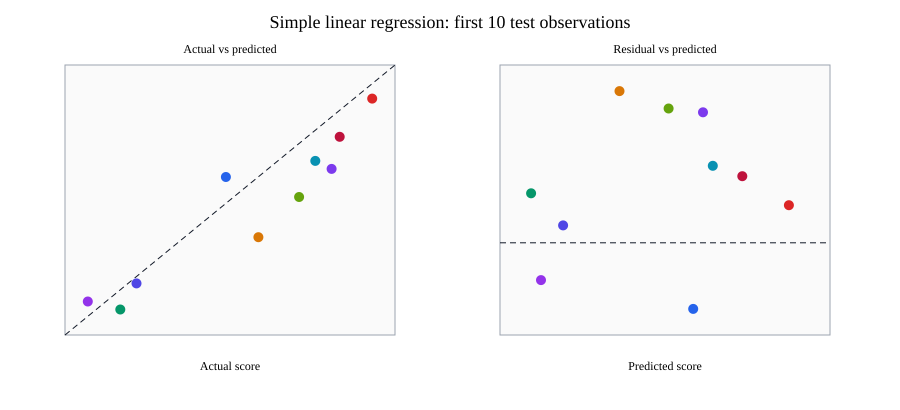

In [3]:
simple_features = ["study_hours"]
simple_coefficients = fit_linear(simple_features)
y_test = [rows[i]["final_score"] for i in test_indices]
simple_predictions = [predict(simple_coefficients, rows[i], simple_features) for i in test_indices]
simple_mse, simple_r2 = regression_metrics(y_test, simple_predictions)
print(f"Model: final_score = {simple_coefficients[0]:.3f} + {simple_coefficients[1]:.3f} * study_hours")
print(f"Test mean squared error (MSE): {simple_mse:.3f}")
print(f"Test R-squared: {simple_r2:.4f}")
show_plot(y_test, simple_predictions, "Simple linear regression")

## 2. Multiple linear regression

Predict `final_score` from study hours, attendance, previous score, and assignment completion. MSE is the mean squared prediction error (in score-points squared); R-squared summarizes the share of score variation explained by the model. The diagnostic plot shows actual versus predicted scores and residuals for 10 test observations.

Intercept: 9.624
study_hours coefficient: 2.979
attendance_pct coefficient: 0.200
previous_score coefficient: 0.337
assignments_completed_pct coefficient: 0.153
Test mean squared error (MSE): 32.581
Test R-squared: 0.8227

First 10 test observations (residual = actual - predicted):
    Actual    Predicted   Residual
      74.0        83.05      -9.05
      92.0        89.94       2.06
      61.0        70.49      -9.49
      57.0        64.95      -7.95
      78.0        69.88       8.12
      85.0        80.37       4.63
      63.0        55.40       7.60
      88.0        90.52      -2.52
      83.0        74.13       8.87
      87.0        85.44       1.56


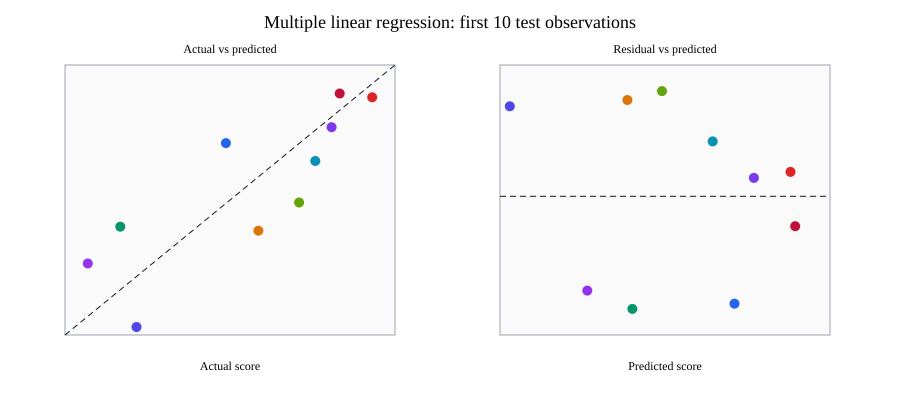

In [4]:
predictors = [
    "study_hours",
    "attendance_pct",
    "previous_score",
    "assignments_completed_pct",
]
multiple_coefficients = fit_linear(predictors)
multiple_predictions = [predict(multiple_coefficients, rows[i], predictors) for i in test_indices]
multiple_mse, multiple_r2 = regression_metrics(y_test, multiple_predictions)
print(f"Intercept: {multiple_coefficients[0]:.3f}")
for name, coefficient in zip(predictors, multiple_coefficients[1:]):
    print(f"{name} coefficient: {coefficient:.3f}")
print(f"Test mean squared error (MSE): {multiple_mse:.3f}")
print(f"Test R-squared: {multiple_r2:.4f}")
show_plot(y_test, multiple_predictions, "Multiple linear regression")
print("\nFirst 10 test observations (residual = actual - predicted):")
print(f"{'Actual':>10} {'Predicted':>12} {'Residual':>10}")
for actual, predicted in list(zip(y_test, multiple_predictions))[:10]:
    print(f"{actual:10.1f} {predicted:12.2f} {actual - predicted:10.2f}")

## 3. Logistic regression

Predict whether a student passed (1) or did not pass (0) with logistic regression trained by gradient descent. Accuracy and the confusion matrix compare predictions with the held-out test labels; precision and recall are also reported.

In [5]:
feature_means = [sum(rows[i][name] for i in train_indices) / len(train_indices) for name in predictors]
feature_stds = [
    (sum((rows[i][name] - mean) ** 2 for i in train_indices) / len(train_indices)) ** 0.5
    for name, mean in zip(predictors, feature_means)
]
weights = [0.0] * len(predictors)
bias = 0.0
learning_rate = 0.1
for _ in range(3000):
    grad_w = [0.0] * len(weights)
    grad_b = 0.0
    for i in train_indices:
        x = [(rows[i][name] - mean) / std for name, mean, std in zip(predictors, feature_means, feature_stds)]
        z = max(-30.0, min(30.0, bias + sum(w * value for w, value in zip(weights, x))))
        probability = 1 / (1 + math.exp(-z))
        error = probability - rows[i]["passed"]
        grad_b += error
        for j, value in enumerate(x):
            grad_w[j] += error * value
    bias -= learning_rate * grad_b / len(train_indices)
    weights = [w - learning_rate * grad / len(train_indices) for w, grad in zip(weights, grad_w)]
actual_pass = [rows[i]["passed"] for i in test_indices]
pass_predictions = []
for i in test_indices:
    x = [(rows[i][name] - mean) / std for name, mean, std in zip(predictors, feature_means, feature_stds)]
    z = max(-30.0, min(30.0, bias + sum(w * value for w, value in zip(weights, x))))
    pass_predictions.append(int(1 / (1 + math.exp(-z)) >= 0.5))
accuracy = sum(a == p for a, p in zip(actual_pass, pass_predictions)) / len(actual_pass)
tn = sum(a == 0 and p == 0 for a, p in zip(actual_pass, pass_predictions))
fp = sum(a == 0 and p == 1 for a, p in zip(actual_pass, pass_predictions))
fn = sum(a == 1 and p == 0 for a, p in zip(actual_pass, pass_predictions))
tp = sum(a == 1 and p == 1 for a, p in zip(actual_pass, pass_predictions))
print(f"Test accuracy: {accuracy:.3f}")
print("Confusion matrix (rows = actual [not passed, passed], columns = predicted [not passed, passed]):")
print([[tn, fp], [fn, tp]])
print(f"Passed precision: {tp / (tp + fp):.3f}; recall: {tp / (tp + fn):.3f}")
print(f"Not-passed precision: {tn / (tn + fn):.3f}; recall: {tn / (tn + fp):.3f}")

Test accuracy: 0.896
Confusion matrix (rows = actual [not passed, passed], columns = predicted [not passed, passed]):
[[98, 59], [45, 798]]
Passed precision: 0.931; recall: 0.947
Not-passed precision: 0.685; recall: 0.624


## Dataset columns

- `student_id`: fictional, unique student identifier.
- `study_hours`: weekly study hours.
- `attendance_pct`: percentage of classes attended.
- `previous_score`: score on a previous assessment (0–100).
- `assignments_completed_pct`: percentage of assignments completed.
- `final_score`: fictional final assessment score (0–100), the continuous target.
- `passed`: binary target derived from `final_score` (1 if at least 60, otherwise 0).

Because the records are fictional, do not interpret model results as evidence about real students.